In [1]:
# Visualization parameters (ref. Fig_03 interaction_distribution)
from pathlib import Path
PACKAGE_ROOT = next((path for path in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (path / "interactions").is_dir()), None)
if PACKAGE_ROOT is None:
    raise FileNotFoundError("Run this notebook from inside AIJ_fig_submit.")
GENERALIZATION_ROOT = PACKAGE_ROOT / "interactions" / "generalization"
OUTPUT_DIR = PACKAGE_ROOT / "Fig_09_correctness" / "outputs"
CACHE_DIR = PACKAGE_ROOT / "Fig_09_correctness" / "source" / ".cache"
N_DIM = 10
FONT_SIZE = 9
BAR_WIDTH = 0.72

# Layout matching Fig_03 cell1 design
SUBPLOT_WIDTH = 1.5
SUBPLOT_HEIGHT = 1.0
WSPACE_INCHES = 0.12       # gap within each Correct/Incorrect pair
HSPACE_INCHES = 0.24
GROUP_GAP_INCHES = 0.5    # gap between the three major groups
LEFT_MARGIN = 0.15
RIGHT_MARGIN = 0.02
TOP_MARGIN = 0.02
BOTTOM_MARGIN = 0.2

MODELS = [
    {
        "label": "ResNet-20\nCIFAR-10",
        "root": GENERALIZATION_ROOT / "harsanyi_spilt_adv/split_baseline/dataset=cifar10_split_model=resnet20_epoch=200_bs=128_lr=0.01_weight-decay=0.0005_seed=0_noise-label=False_step-size=4.0_epsilon=64.0_n-step=1",
        "prefix": "class-",
        "tau": 0.03,
        "set_predict_tau": None,
    },
    {
        "label": "VGG-11\nCIFAR-10",
        "root": GENERALIZATION_ROOT / "harsanyi_spilt_adv/split_baseline/dataset=cifar10_split_model=vgg11_epoch=80_bs=128_lr=0.01_weight-decay=0.0005_seed=0_noise-label=False_step-size=4.0_epsilon=64.0_n-step=1",
        "prefix": "class-",
        "tau": 0.03,
        "set_predict_tau": None,
    },
    {
        "label": "Bert-Medium\nSST-2",
        "root": GENERALIZATION_ROOT / "harsanyi_spilt/split_baseline/dataset=SST-2_model=bert-medium_epoch=10_bs=128_lr=0.01_seed=0_noise-label=False/dataset=SST-2_model=bert-medium_epoch=30_bs=128_lr=0.01_seed=0_noise-label=False",
        "prefix": None,
        "tau": 0.0,
        "set_predict_tau": 0.03,
    },
    {
        "label": "Bert-Base\nSST-2",
        "root": GENERALIZATION_ROOT / "harsanyi_spilt/split_baseline/dataset=SST-2_model=bert-base_epoch=10_bs=64_lr=0.01_seed=0_noise-label=False",
        "prefix": None,
        "tau": 0.01,
        "set_predict_tau": 0.03,
    },
]

# Color palette from Fig_03
ORIG_COLORS = {
    "all_pos": "#CE593B",
    "all_neg": "#F6CDBF",
    "gen_pos": "#4B73C3",
    "gen_neg": "#A9C0EE",
}

# (group_id, pos_key, neg_key, pos_color_key, neg_color_key)
GROUPS = [
    ("all", "all_pos", "all_neg", "all_pos", "all_neg"),
    ("decay", "gen_pos", "gen_neg", "gen_pos", "gen_neg"),
    ("spindle", "gen_pos", "gen_neg", "gen_pos", "gen_neg"),
]

N_ROWS = len(MODELS)
N_COLS = 6
FIGWIDTH = LEFT_MARGIN + N_COLS * SUBPLOT_WIDTH + (N_COLS - 1 - 2) * WSPACE_INCHES + 2 * GROUP_GAP_INCHES + RIGHT_MARGIN
FIGHEIGHT = TOP_MARGIN + N_ROWS * SUBPLOT_HEIGHT + (N_ROWS - 1) * HSPACE_INCHES + BOTTOM_MARGIN
FIGSIZE = (FIGWIDTH, FIGHEIGHT)


Processing ResNet-20 CIFAR-10


Processing VGG-11 CIFAR-10


Processing Bert-Medium SST-2


Processing Bert-Base SST-2


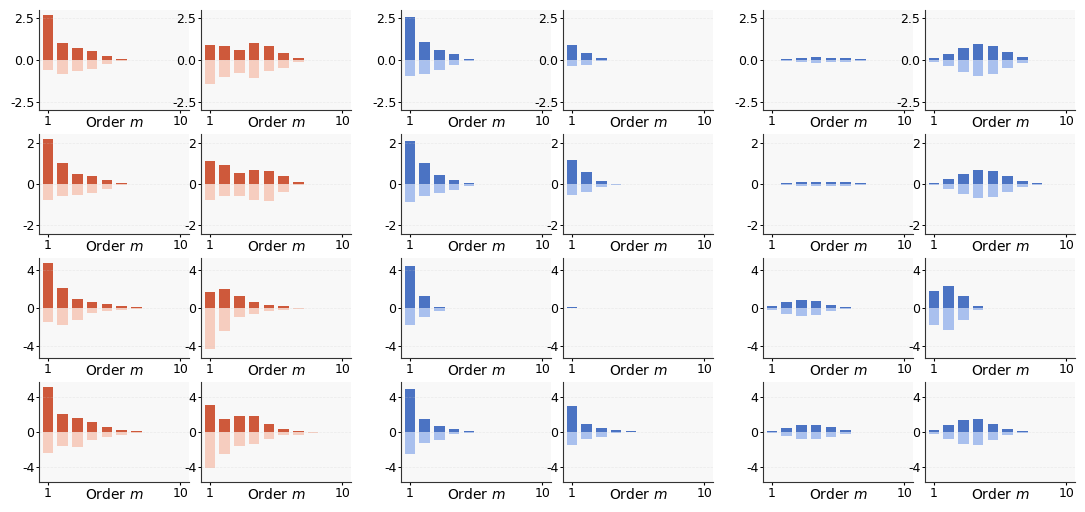

In [2]:
from pathlib import Path
import sys
sys.path.insert(0, str(PACKAGE_ROOT / "shared"))

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

from tool import apply_style, disentangle_correct_incorrect_shared


def load_and_split(root, prefix, tau):
    """Load interactions and split samples by prediction correctness."""
    root = Path(root)
    if prefix:
        clusters = [d for d in root.iterdir() if d.is_dir() and d.name.startswith(prefix)]
        sample_dirs = [sample for cluster in clusters for sample in cluster.iterdir() if sample.is_dir()]
    else:
        sample_dirs = [d for d in root.iterdir() if d.is_dir()]

    correct_and, correct_or = [], []
    incorrect_and, incorrect_or = [], []
    vn_v0_list = []
    masks = None

    for sample_dir in sample_dirs:
        I_and = np.load(sample_dir / "after_sparsify" / "Iand.npy")
        I_or = np.load(sample_dir / "after_sparsify" / "Ior.npy")
        rewards = np.load(sample_dir / "before_sparsify" / "rewards.npy")
        if masks is None:
            masks = np.load(sample_dir / "before_sparsify" / "masks.npy")

        if prefix is None:
            flag = rewards[-1] > 0
        elif prefix == "class-":
            gt = sample_dir.parent.name.split("-")[1][0]
            model_output = sample_dir / "model_output.txt"
            with open(model_output, "r") as f:
                lines = f.read()
            output = eval(lines[8:-3])
            predict = np.argmax(output).item()
            flag = int(gt) == predict
        else:
            raise ValueError(f"Unsupported prefix: {prefix}")

        if flag:
            correct_and.append(I_and)
            correct_or.append(I_or)
        else:
            incorrect_and.append(I_and)
            incorrect_or.append(I_or)
        vn_v0_list.append(np.abs(rewards[0] - rewards[-1]))

    vn_v0_list = np.array(vn_v0_list)
    threshold = np.mean(vn_v0_list) * tau

    correct_and = np.array(correct_and)
    correct_or = np.array(correct_or)
    incorrect_and = np.array(incorrect_and)
    incorrect_or = np.array(incorrect_or)

    correct_and[np.abs(correct_and) < threshold] = 0
    correct_or[np.abs(correct_or) < threshold] = 0
    incorrect_and[np.abs(incorrect_and) < threshold] = 0
    incorrect_or[np.abs(incorrect_or) < threshold] = 0

    return correct_and, correct_or, incorrect_and, incorrect_or, masks


apply_style(FONT_SIZE)

# Local style overrides to match Fig_03 reference figure
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 9,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "axes.edgecolor": "#333333",
    "xtick.major.size": 2.5,
    "ytick.major.size": 2.5,
    "ytick.major.width": 0.7,
    "grid.alpha": 0.3,
    "grid.linewidth": 0.5,
    "grid.color": "#CCCCCC",
    "figure.facecolor": "white",
    "axes.facecolor": "#F8F8F8",
})

OUTPUT_DIR = Path(OUTPUT_DIR)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR = Path(CACHE_DIR)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

results = []
for config in MODELS:
    print(f"Processing {config['label'].replace(chr(10), ' ')}")
    c_and, c_or, i_and, i_or, masks = load_and_split(
        config["root"], config["prefix"], config["tau"]
    )
    cache_name = config["label"].replace("\n", "-").replace(" ", "-")
    cache_dir = CACHE_DIR / cache_name
    res = disentangle_correct_incorrect_shared(
        c_and, c_or, i_and, i_or, masks,
        cache_dir=cache_dir,
        tau=config["tau"],
        set_predict_tau=config["set_predict_tau"],
    )
    results.append(
        {
            "label": config["label"],
            "res": res,
            "correct_n": len(c_and),
            "incorrect_n": len(i_and),
        }
    )

fig = plt.figure(figsize=FIGSIZE)

# Compute exact column left positions (in inches), with larger gaps between groups
col_lefts = []
x = LEFT_MARGIN
for c in range(N_COLS):
    col_lefts.append(x)
    gap = GROUP_GAP_INCHES if c in (1, 3) else WSPACE_INCHES
    x += SUBPLOT_WIDTH + gap

# Compute exact row bottom positions (in inches), from top to bottom
row_bottoms = []
y = FIGHEIGHT - TOP_MARGIN - SUBPLOT_HEIGHT
for r in range(N_ROWS):
    row_bottoms.append(y)
    y -= (SUBPLOT_HEIGHT + HSPACE_INCHES)

# Create axes manually so that group gaps can be controlled precisely
axes = [[None] * N_COLS for _ in range(N_ROWS)]
for r in range(N_ROWS):
    for c in range(N_COLS):
        left = col_lefts[c] / FIGWIDTH
        bottom = row_bottoms[r] / FIGHEIGHT
        width = SUBPLOT_WIDTH / FIGWIDTH
        height = SUBPLOT_HEIGHT / FIGHEIGHT
        axes[r][c] = fig.add_axes([left, bottom, width, height])

for r, result in enumerate(results):
    res = result["res"]
    for c in range(N_COLS):
        ax = axes[r][c]
        group_idx = c // 2
        is_correct = (c % 2) == 0
        split = "correct" if is_correct else "incorrect"
        _, pos_key, neg_key, pos_color_key, neg_color_key = GROUPS[group_idx]
        pos = res[split]["decay_pos"] if group_idx == 1 else res[split]["spindle_pos"] if group_idx == 2 else res[split][pos_key]
        neg = res[split]["decay_neg"] if group_idx == 1 else res[split]["spindle_neg"] if group_idx == 2 else res[split][neg_key]

        x = np.arange(1, len(pos) + 1)
        ax.bar(x, pos, width=BAR_WIDTH, color=ORIG_COLORS[pos_color_key], edgecolor="none")
        ax.bar(x, -neg, width=BAR_WIDTH, color=ORIG_COLORS[neg_color_key], edgecolor="none")
        ax.set_xlim(0.4, len(pos) + 0.6)
        ax.set_xticks([1, len(pos)])
        ax.tick_params(pad=1)
        ax.yaxis.set_major_locator(MaxNLocator(nbins=3))
        ax.set_xlabel(r"Order $m$", fontsize=10)
        ax.xaxis.set_label_coords(0.5, -0.05)

    all_vals = []
    for split in ["correct", "incorrect"]:
        for key in ["all_pos", "all_neg", "decay_pos", "decay_neg", "spindle_pos", "spindle_neg"]:
            all_vals.extend(np.abs(res[split][key]))
    lim = max(all_vals) * 1.12
    for c in range(N_COLS):
        axes[r][c].set_ylim(-lim, lim)

# Save the text-free version preserving exact layout (same as Fig_03)
fig.savefig(OUTPUT_DIR / "main_no_text.pdf", bbox_inches=None, pad_inches=0.0)
fig.savefig(OUTPUT_DIR / "main_no_text.png", bbox_inches=None, pad_inches=0.0, dpi=300)
plt.show()
